# Lecture 2

Load up a nice Python environment, with high-resolution plots for a modern LCD:

In [1]:
%pylab inline
%config InlineBackend.figure_format = 'retina'

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


We are going to be trying to fit and extract some information from the public data released for GW150914.  First a disclaimer: this *is not what LIGO actually does*; our "just so" stories are significantly more sophisticated than what we will do here.  If you want to know what was actually done to fit the recent BBH events, you can read about it in our papers, particularly:

 * The GW150914 discovery paper [here](http://journals.aps.org/prl/abstract/10.1103/PhysRevLett.116.061102)
 * The "parameter estimation" paper for GW150914 [here](https://arxiv.org/abs/1602.03840v2)
 * The discovery papers for [GW151226](http://journals.aps.org/prl/abstract/10.1103/PhysRevLett.116.241103), [GW170104](https://journals.aps.org/prl/abstract/10.1103/PhysRevLett.118.221101), and the lesser-significance (I want to believe it's a gravitational wave, but you are free to form your own opinions) [LVT151012](http://arxiv.org/abs/1606.04856v3)
 
and (of course) references therein.  Here we are just trying to give a flavour of the analysis.

We will be partially following the [BBH Event Tutorial](https://losc.ligo.org/s/events/GW150914/LOSC_Event_tutorial_GW150914.html) from the [LIGO Open Science Center](http://losc.ligo.org) [tutorial](https://losc.ligo.org/tutorials/) page.  I encourage you to read the whole tutorial at LOSC and, generally, to explore our data releases (one for each "GW" event) and the tools we have provided for learning from them.  

You will need to download the large files containing 4096 seconds of data surrounding GW150914 yourself (I am not putting them in the [git repository](https://github.com/farr/GWDataAnalysisSummerSchool) where these lectures are archived because they are quite large):
 * [Hanford data at 4096 Hz sampling](https://losc.ligo.org/s/events/GW150914/H-H1_LOSC_4_V1-1126259446-32.hdf5)
 * [Hanford data at 16384 Hz sampling](https://losc.ligo.org/s/events/GW150914/H-H1_LOSC_16_V1-1126259446-32.hdf5)
 * [Livingston data at 4096 Hz sampling](https://losc.ligo.org/s/events/GW150914/L-L1_LOSC_4_V1-1126259446-32.hdf5)
 * [Livingston data at 16384 Hz sampling](https://losc.ligo.org/s/events/GW150914/L-L1_LOSC_16_V1-1126259446-32.hdf5)
 * [a Python library](https://losc.ligo.org/s/sample_code/readligo.py) to read in the data (you will also need [h5py](http://www.h5py.org) since the data files are stored in HDF5 format).
 
As in lecture 1, you will need to install the [seaborn](https://seaborn.pydata.org) library for pretty and useful statistical plots.

In [2]:
import arviz as az
import corner
import h5py
import jax
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, SVI, Trace_ELBO, Predictive, init_to_value
from numpyro.infer.autoguide import AutoDelta
import scipy.interpolate as si
import scipy.signal as ss
import seaborn as sns
import readligo as rl

numpyro.set_host_device_count(4) # Run four chains in parallel
numpyro.enable_x64() # Double precision

Make the plots pretty for the notebook:

In [3]:
sns.set_context('talk') # sns.set_context('notebook') will work better if you are following along at home
sns.set_style('ticks')
sns.set_palette('colorblind')

In [4]:
strain_h1, time_h1, channels_h1 = rl.loaddata('H-H1_LOSC_4_V1-1126259446-32.hdf5', 'H1')
fsampling = 4096
dt_sampling = time_h1[1]-time_h1[0]

This doesn't look like a gravitational wave at all:

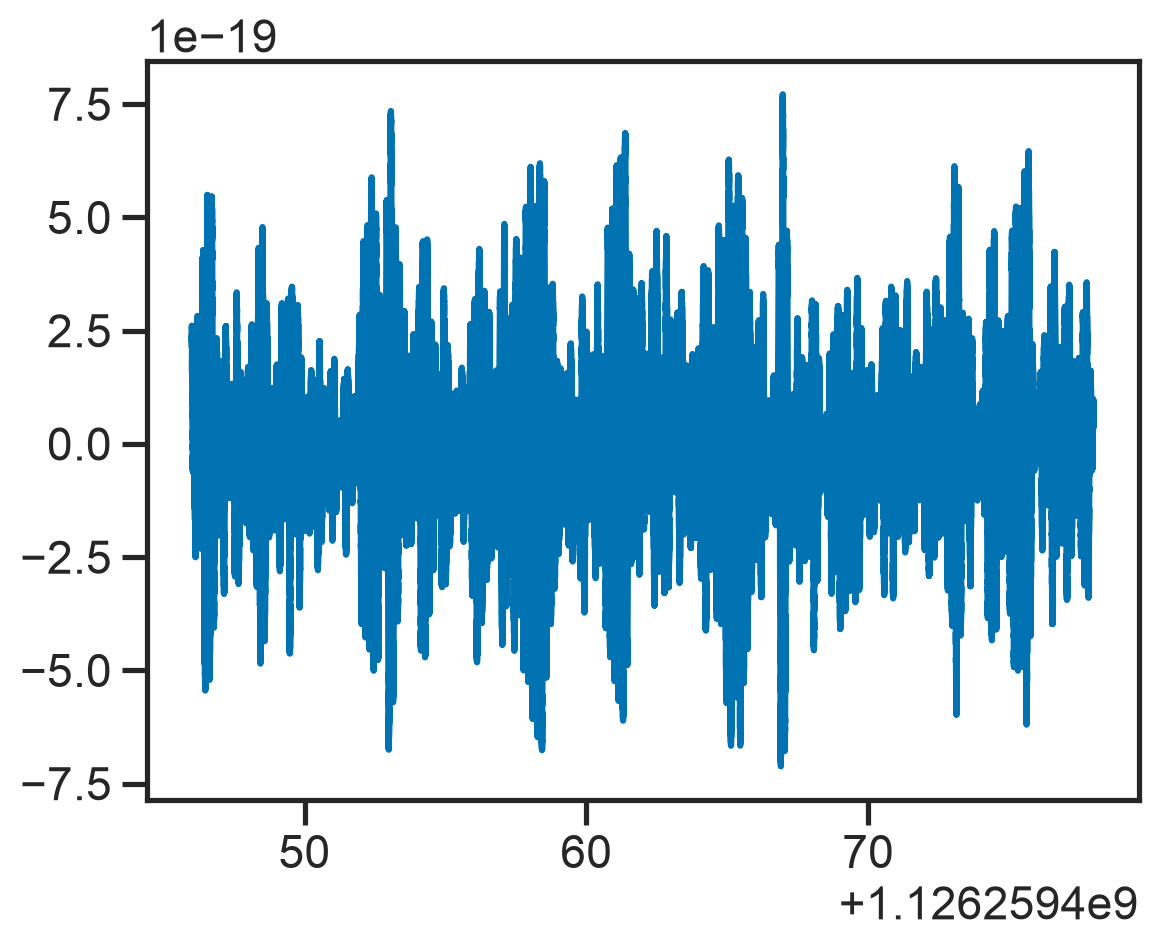

In [5]:
plot(time_h1, strain_h1)

The problem is that the LIGO data are dominated by *low frequency noise*, *calibration lines*, and other *narrowband detector lines*.  Fortunately, none of this noise "looks like" a GW signal.

 * Discuss "PSD," "stationarity," etc.
 * Formalise a bit "looks like."

Let's estimate the PSD for this data.  Since we know in advance that we are going to be interested in about 0.25 seconds around GW150914, we will use this "segment length" in the PSD estimate:

In [6]:
fs, psd_h1 = ss.welch(strain_h1, nperseg=fsampling/4, fs=fsampling)

(np.float64(10.0),
 np.float64(2797.650445833006),
 np.float64(2.2231005898501714e-47),
 np.float64(1e-40))

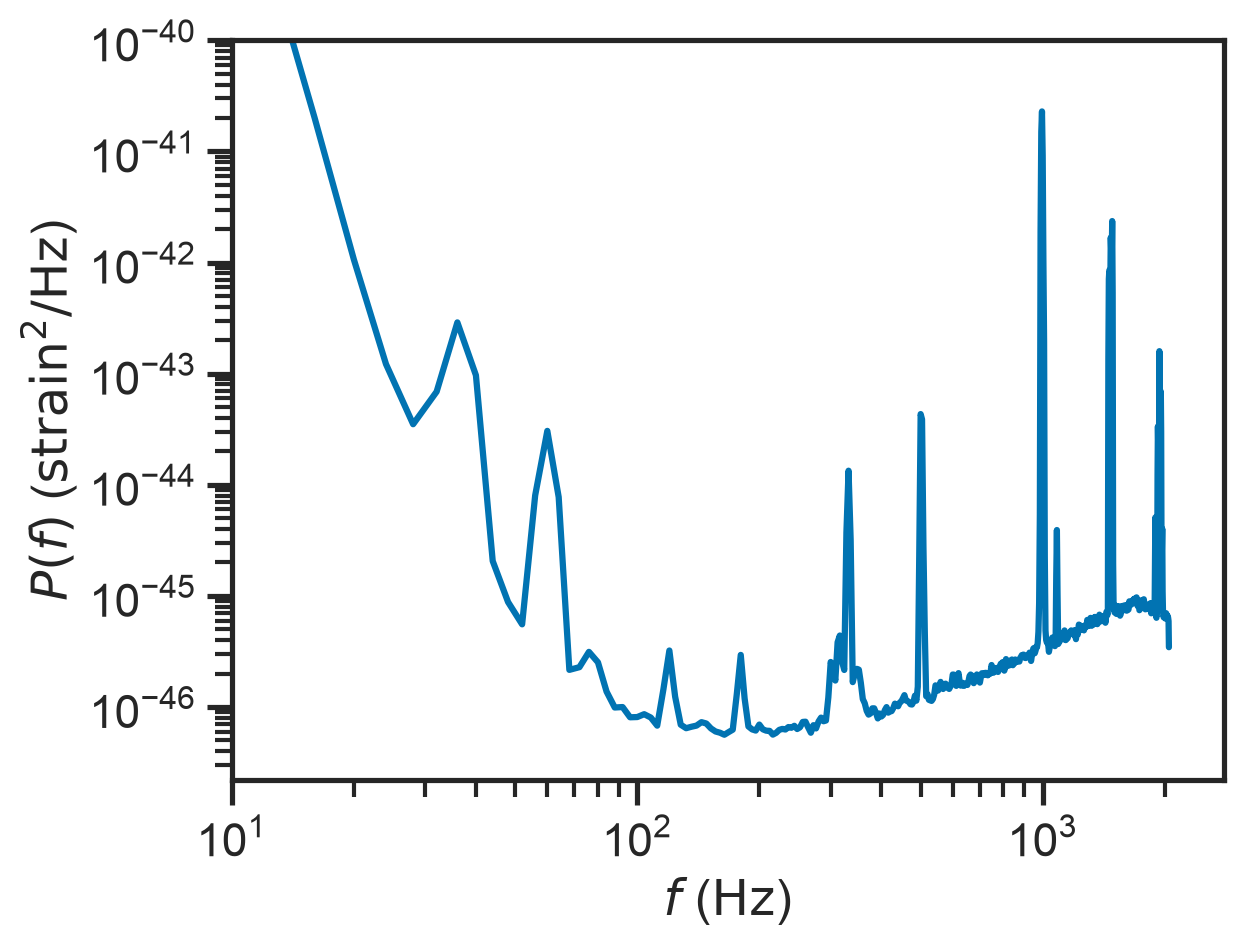

In [7]:
loglog(fs, psd_h1)
ylabel(r'$P(f)$ ($\mathrm{strain}^2 / \mathrm{Hz}$)')
xlabel(r'$f$ ($\mathrm{Hz}$)')
axis(xmin=10, ymax=1e-40)

 * Discussion of whitening

In [8]:
# Copied from LOSC tutorial
def whiten(strain, interp_psd, dt):
    Nt = len(strain)
    freqs = np.fft.rfftfreq(Nt, dt)

    # whitening: transform to freq domain, divide by asd, then transform back, 
    # taking care to get normalization right.
    hf = np.fft.rfft(strain)
    white_hf = hf / (np.sqrt(interp_psd(freqs) /dt/2.))
    white_ht = np.fft.irfft(white_hf, n=Nt)
    return white_ht

In [9]:
white_strain_h1 = whiten(strain_h1, si.interp1d(fs, psd_h1), dt_sampling)

In [10]:
tGW150914 = 1126259462.422
tselector = (time_h1 > tGW150914-0.2) & (time_h1 < tGW150914+0.05)

Hmmm....

Text(0, 0.5, 'Whitened Strain')

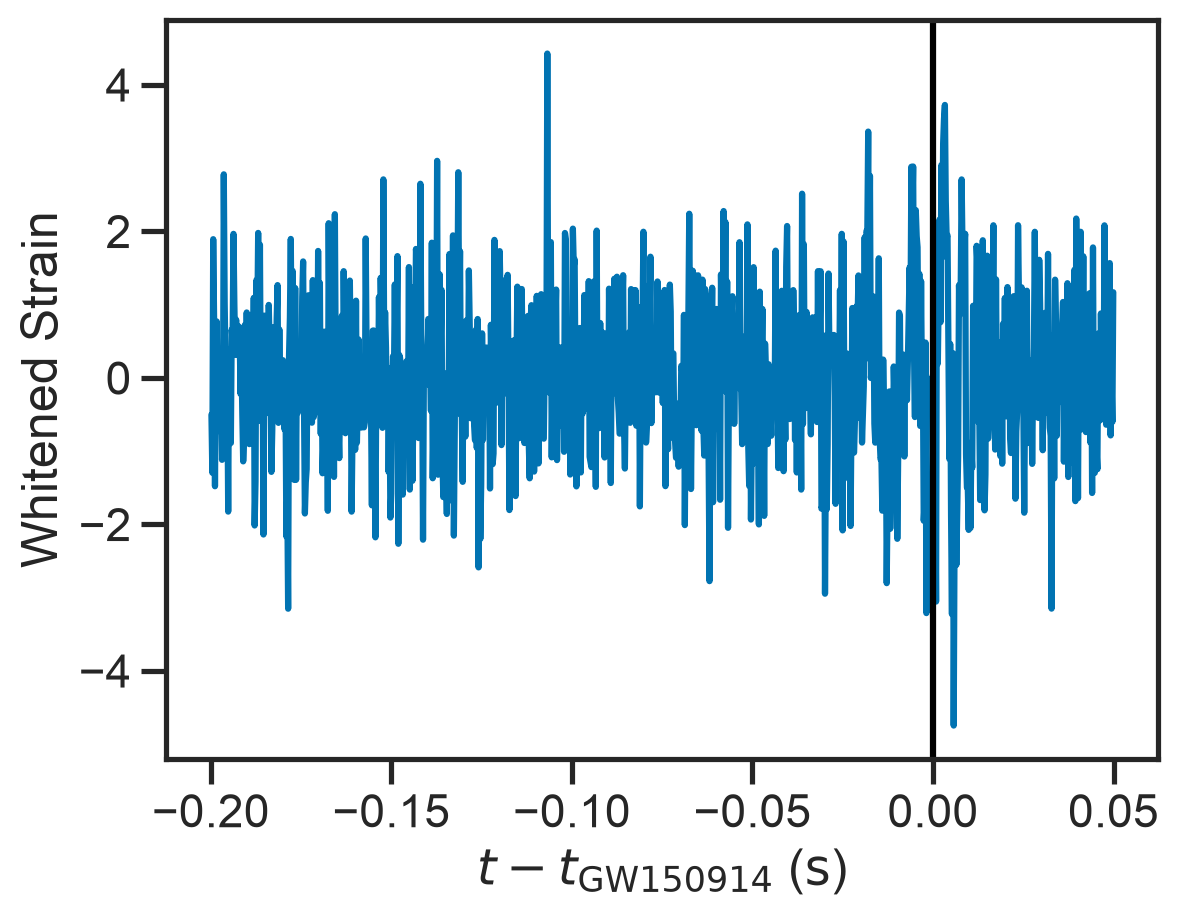

In [11]:
plot(time_h1[tselector]-tGW150914, white_strain_h1[tselector])
axvline(0.0, color='k')
xlabel(r'$t-t_\mathrm{GW150914}$ ($\mathrm{s}$)')
ylabel(r'Whitened Strain')

There is lots of high-frequency noise here, but perhaps there is something where I have drawn the line.  Since we know that the signal is low-frequency (i.e. high-mass), let's low-pass filter it.  Note that this messes up the normalisation of the whitening we did earlier.  Roughly, we are averaging over four neighbouring data points, which will reduce our uncertainty from $\sigma = 1$ to $\sigma = 1/2$.

In [12]:
def low_pass_filter_amplitude(fs, frolloff, fwidth):
    return 1.0/(1.0 + jnp.exp((fs - frolloff)/fwidth))
def low_pass_filter(data, dt):
    Nt = data.shape[0]
    fs = np.fft.rfftfreq(Nt, dt)
    
    filt = low_pass_filter_amplitude(fs, 512.0, 16.0) # Rolloff at 512 Hz over 16 Hz
    
    dataf = np.fft.rfft(data)
    return np.fft.irfft(dataf*filt, Nt)

Once we low-pass filter the data, we can downsample it by a factor of four; we will also create a zero-centred time series at the same sample rate called `white_pass_time`:

In [13]:
white_pass_strain_h1 = low_pass_filter(white_strain_h1, dt_sampling)
white_pass_strain_h1 = white_pass_strain_h1[tselector][::4]
white_pass_time = time_h1[tselector]-tGW150914
white_pass_time = white_pass_time[::4]

Text(0, 0.5, 'Whitened Strain')

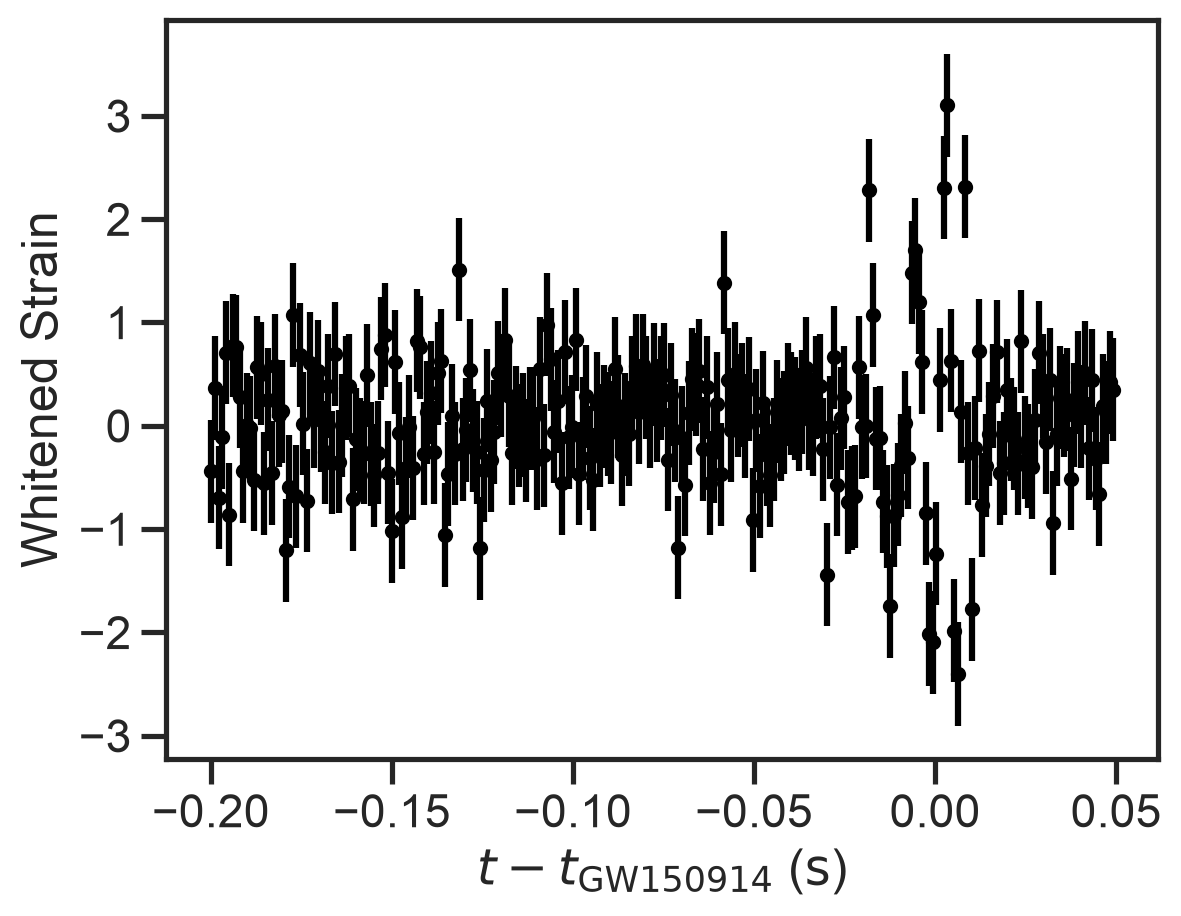

In [14]:
errorbar(white_pass_time, white_pass_strain_h1, 0.5, fmt='.', color='k')
xlabel(r'$t-t_\mathrm{GW150914}$ ($\mathrm{s}$)')
ylabel(r'Whitened Strain')

["Basic physics" paper](https://arxiv.org/pdf/1608.01940.pdf) discussion; for "real" post Newtonian expansions, see [Blanchet (2014)](https://link.springer.com/content/pdf/10.12942%2Flrr-2014-2.pdf)

The basic physics paper gives the evolution of the *inspiral* phase with time:

/var/folders/70/vvk0t38122l6ddxl8hbymr480000gp/T/ipykernel_87192/1221916295.py:2: RuntimeWarning: invalid value encountered in power
  fs = (1100.0*(4.9e-6*20.0)**(5.0/3.0)*(-ts))**(-3.0/8.0)


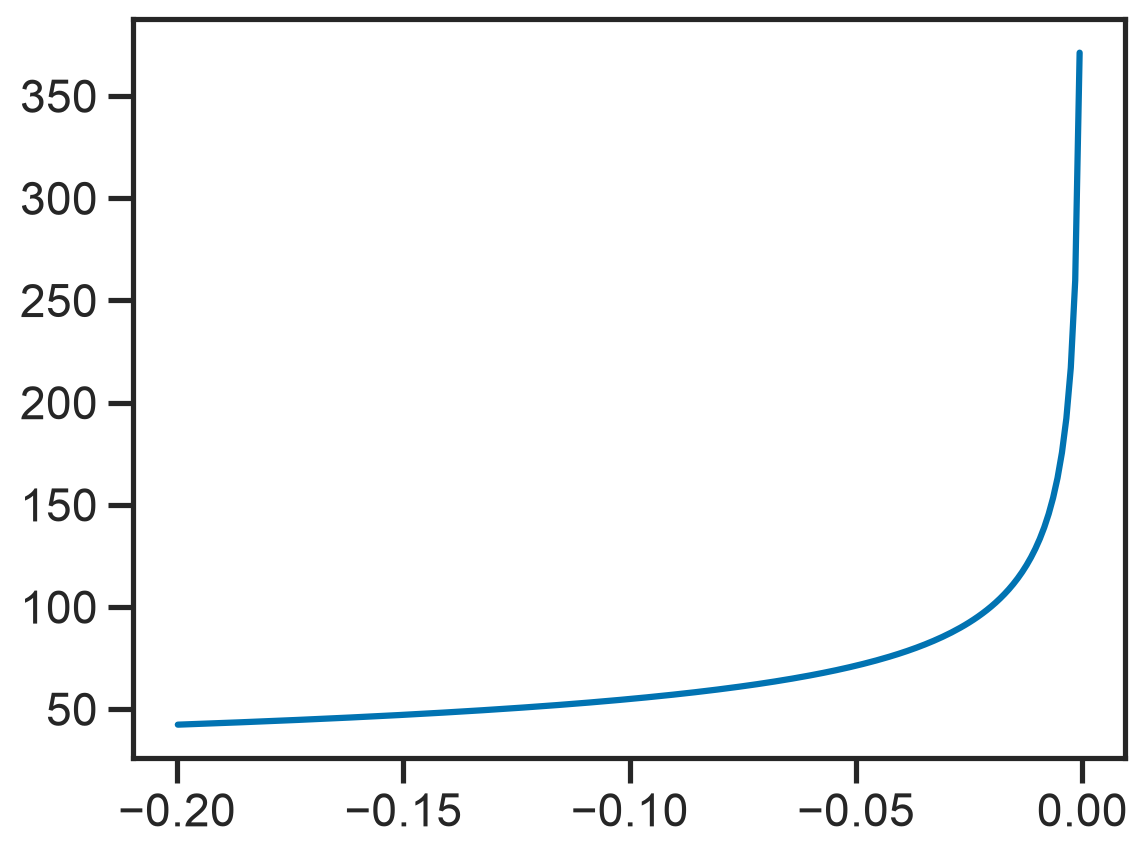

In [15]:
ts = white_pass_time
fs = (1100.0*(4.9e-6*20.0)**(5.0/3.0)*(-ts))**(-3.0/8.0)
plot(ts, fs)

Edited 2017 July 19: Originally I did something silly here, which was to calculate the phase $\Phi(t) = \Phi_0 + 2\pi f(t) \left(t-t_0\right)$, but this is incorrect; really 
$$
\Phi(t) = 2 \pi \int^t \mathrm{d} s \, f(s).
$$
The difference between the integral and multiplying by $t-t_0$ is a constant factor that is likely responsible for the too-small chirp mass I found.  

Because the inspiral frequency reaches $\infty$ in finite time, we will have to do something.  After some discussion, we ended up choosing:
 * To truncate the frequency at some $f_\mathrm{max}$ (a parameter).
 * To have an exponentially-damped amplitude decay once the frequency reaches $f_\mathrm{max}$.
 * To use a power-law amplitude with unknown index.

So
$$
h(t) = A_{100} \left( \frac{f(t)}{100 \, \mathrm{Hz}} \right)^\alpha \cos \left( \phi_0 + \Phi(t) \right) \frac{1}{1 + \exp\left( \frac{t - t\left(f_\mathrm{max}\right)}{\tau} \right)}
$$
with
$$
f(t) = \begin{cases}
\left( \frac{\left( 8 \pi \right)^{8/3}}{5} \left( \frac{G \mathcal{M}}{c^3} \right)^{5/3} \left( t_c - t \right) \right)^{-3/8} & f(t) < f_\mathrm{max} \\
f_\mathrm{max} & \mathrm{otherwise}
\end{cases}
$$

In [16]:
def basic_waveform(ts, A100, dlnAdlnf, Mc, tc, phic, max_freq, tau):
    fs = (1100.0*(4.9e-6*Mc)**(5.0/3.0)*(tc-ts))**(-3.0/8.0)

    tmax = tc - max_freq**(-8.0/3.0)/(1100.0*(4.9e-6*Mc)**(5.0/3.0))
    
    Phiinsp = 2.0*pi*8.0/5.0*(1100.0*(4.9e-6*Mc)**(5.0/3.0))**(-3.0/8.0)*(tc - ts)**(5.0/8.0)
    Phiconst = 2.0*pi*8.0/5.0*(1100.0*(4.9e-6*Mc)**(5.0/3.0))**(-3.0/8.0)*(tc - tmax)**(5.0/8.0) + 2.0*pi*max_freq*(tmax-ts)
    
    Phi = where(ts < tmax, Phiinsp, Phiconst)
        
    fs[(fs >= max_freq) | (ts >= tc)] = max_freq
    
    amps = A100*(fs/100)**dlnAdlnf
    
    return (1.0-low_pass_filter_amplitude(fs, 30.0, 2.0))*amps*cos(phic - Phi)*low_pass_filter_amplitude(ts, tmax, tau)

Here is a demonstration of the waveform, showing that it's reasonable---though hardly optimal.

/var/folders/70/vvk0t38122l6ddxl8hbymr480000gp/T/ipykernel_87192/1335699111.py:2: RuntimeWarning: invalid value encountered in power
  fs = (1100.0*(4.9e-6*Mc)**(5.0/3.0)*(tc-ts))**(-3.0/8.0)
/var/folders/70/vvk0t38122l6ddxl8hbymr480000gp/T/ipykernel_87192/1335699111.py:6: RuntimeWarning: invalid value encountered in power
  Phiinsp = 2.0*pi*8.0/5.0*(1100.0*(4.9e-6*Mc)**(5.0/3.0))**(-3.0/8.0)*(tc - ts)**(5.0/8.0)


Text(0, 0.5, 'Whitened Strain')

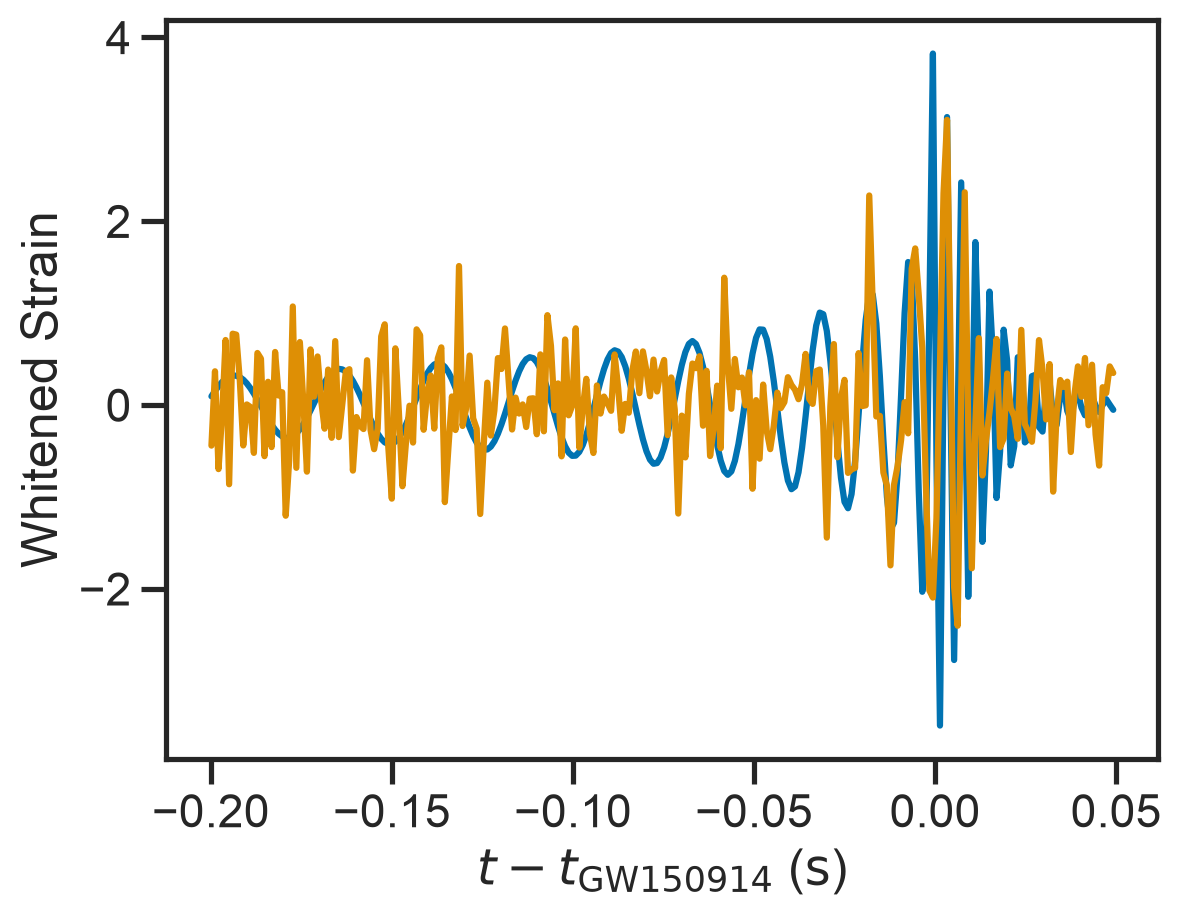

In [17]:
plot(white_pass_time, basic_waveform(white_pass_time, 2.0, 1.5, 30.0, 0.0, 2.0, 250.0, 0.01))
plot(white_pass_time, white_pass_strain_h1)
xlabel(r'$t-t_\mathrm{GW150914}$ ($\mathrm{s}$)')
ylabel(r'Whitened Strain')

And it is implemented in our NumPyro model:

In [18]:
def model(nt, ts, h_obs):
    A100 = numpyro.sample('A100', dist.LogNormal(0.0, 1.0))
    dlnAdlnf = numpyro.sample('dlnAdlnf', dist.LogNormal(0.0, 1.0))
    phi = numpyro.sample('phi', dist.Uniform(0.0, 2.0*pi)) # Phase at 100 Hz, since the phase is set to zero at f = 100 Hz
    tc = numpyro.sample('tc', dist.Normal(0.0, 0.01))
    Mc = numpyro.sample('Mc', dist.LogNormal(log(30.0), 0.2))
    max_freq = numpyro.sample('max_freq', dist.ImproperUniform(dist.constraints.greater_than(100.0), (), ()))
    numpyro.factor('max_freq_prior', dist.LogNormal(log(250.0), 0.5).log_prob(max_freq))
    tau = numpyro.sample('tau', dist.LogNormal(log(5e-3), log(2.0)))
    sigma = numpyro.sample('sigma', dist.LogNormal(0.0, 1.0))

    C = (8.0*pi)**(8.0/3.0)/5.0
    tM53 = (4.9e-6*Mc)**(5.0/3.0) # s^(5/3)
    tm = tc - max_freq**(-8.0/3.0)/(C*tM53) # Time at which f = max_freq
    t100 = 100.0**(-8.0/3.0)/(C*tM53) # Time before tc at which f = 100 Hz
    tleft = jnp.maximum(tc - ts, tc - tm) # Time before tc, frozen once f = max_freq

    fs = (C*tM53*tleft)**(-3.0/8.0)
    # Phase set to be zero at f = 100 Hz; grows at 2*pi*max_freq after tm.
    Phis = 2.0*pi*8.0/5.0*(C*tM53)**(-3.0/8.0)*(tleft**(5.0/8.0) - t100**(5.0/8.0)) + 2.0*pi*max_freq*jnp.minimum(tm - ts, 0.0)
    amps = A100*(fs/100.0)**dlnAdlnf

    # Model rolls "on" at f = (30 +/- 2) Hz and "off" at time of f = fmax with width tau.
    h_model = numpyro.deterministic('h_model', (1.0 - low_pass_filter_amplitude(fs, 30.0, 2.0))*amps*jnp.cos(phi - Phis)*low_pass_filter_amplitude(ts, tm, tau))

    numpyro.sample('h_obs', dist.Normal(h_model, sigma), obs=h_obs)

A fit.  This problem is significantly harder than the linear fits we have been doing, so expect

 1. It will take several minutes.
 1. The sampler may need a longer number of steps to properly warm up and draw independent samples from the data.  Because we don't need so many output points, we can `thin` the output, recording only every $N$-th step.

In [19]:
data = {
    'nt': len(white_pass_time),
    'ts': white_pass_time,
    'h_obs': white_pass_strain_h1
}

This fit turns out to be quite a pain, so let's initialise near a maximum of the parameter space.  We make a good guess (well, we know from PE, searches, the basic physics paper, etc) at the parameters, and ask NumPyro to optimize the model (this may require several calls, with different guesses, until you get a "good looking" waveform).  Once I get a "good" waveform, I accumulate it into an `init` array; all four chains of the sampling will start from the last `init` component:

In [20]:
init = []

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [00:00<00:00, 12342.36it/s, init loss: 538.1850, avg. loss [9501-10000]: 191.8843]


Chirp mass found = 36


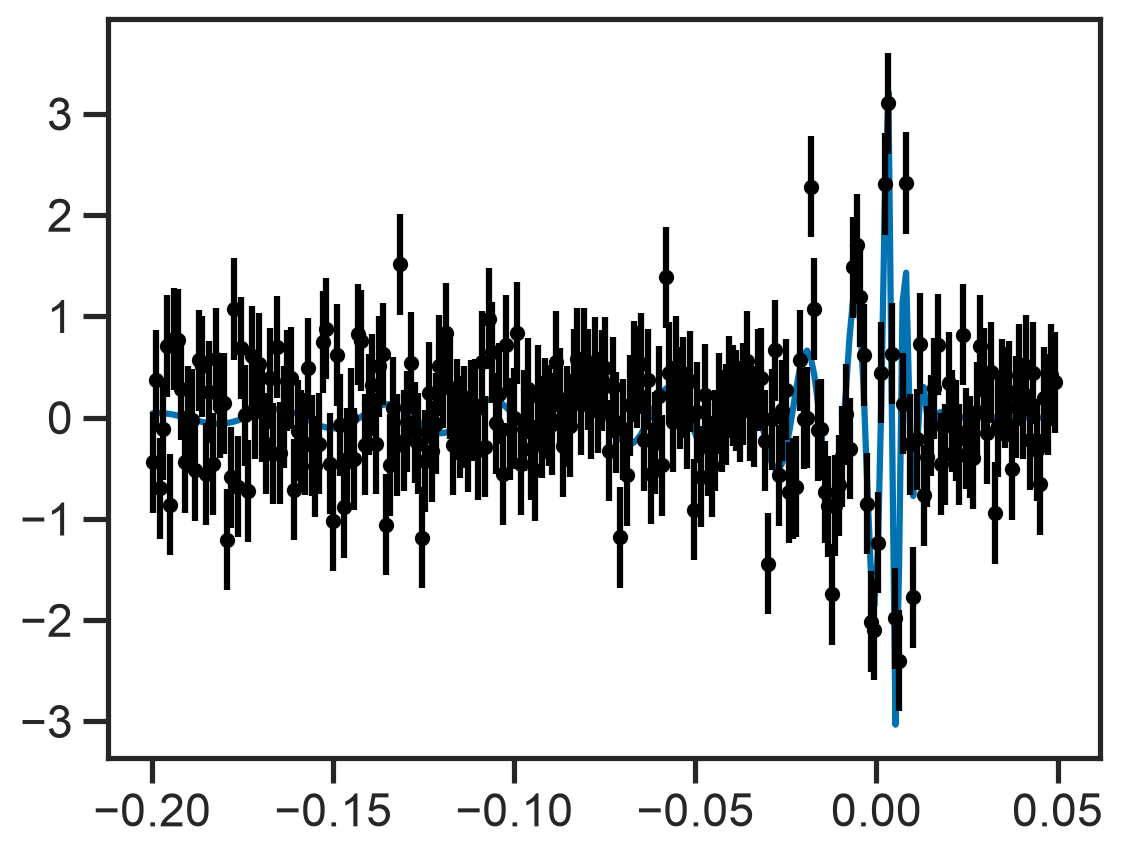

In [21]:
guide = AutoDelta(model, init_loc_fn=init_to_value(values={
    'A100': 2.0,
    'dlnAdlnf': 1.5,
    'phi': 3,
    'tc': 0.003,
    'Mc': 30.0,
    'max_freq': 250,
    'tau': 0.01,
    'sigma': 0.5
}))
svi_result = SVI(model, guide, numpyro.optim.Adam(3e-3), Trace_ELBO()).run(jax.random.PRNGKey(0), 10000, **data)
opt = guide.median(svi_result.params)
opt['h_model'] = Predictive(model, opt, batch_ndims=0)(jax.random.PRNGKey(0), **data)['h_model']
plot(data['ts'], opt['h_model'])
errorbar(data['ts'], data['h_obs'], 0.5, fmt='.', color='k')
print('Chirp mass found = {:.2g}'.format(opt['Mc']))

Every "good looking" waveform above gets accumulated here:

In [22]:
init.append(opt)
len(init)

1

Now that we seem to have a reasonable fit, we will use that for the starting point of the analysis:

In [23]:
fit = MCMC(NUTS(model, init_strategy=init_to_value(values=init[-1])), num_warmup=1000, num_samples=1000, num_chains=4)
fit.run(jax.random.PRNGKey(0), **data)
fit.print_summary()

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
      A100      1.69      0.16      1.68      1.43      1.94   1981.38      1.00
        Mc     36.07      1.01     36.05     34.45     37.68   1795.30      1.00
  dlnAdlnf      2.22      0.19      2.21      1.89      2.52   1841.23      1.00
  max_freq    205.44     12.09    204.49    185.26    225.57   1375.81      1.00
       phi      1.94      0.24      1.93      1.54      2.34   1587.00      1.00
     sigma      0.51      0.02      0.51      0.47      0.55   2456.96      1.00
       tau      0.00      0.00      0.00      0.00      0.00   2264.73      1.00
        tc      0.01      0.00      0.01      0.00      0.01   1278.37      1.00

Number of divergences: 0


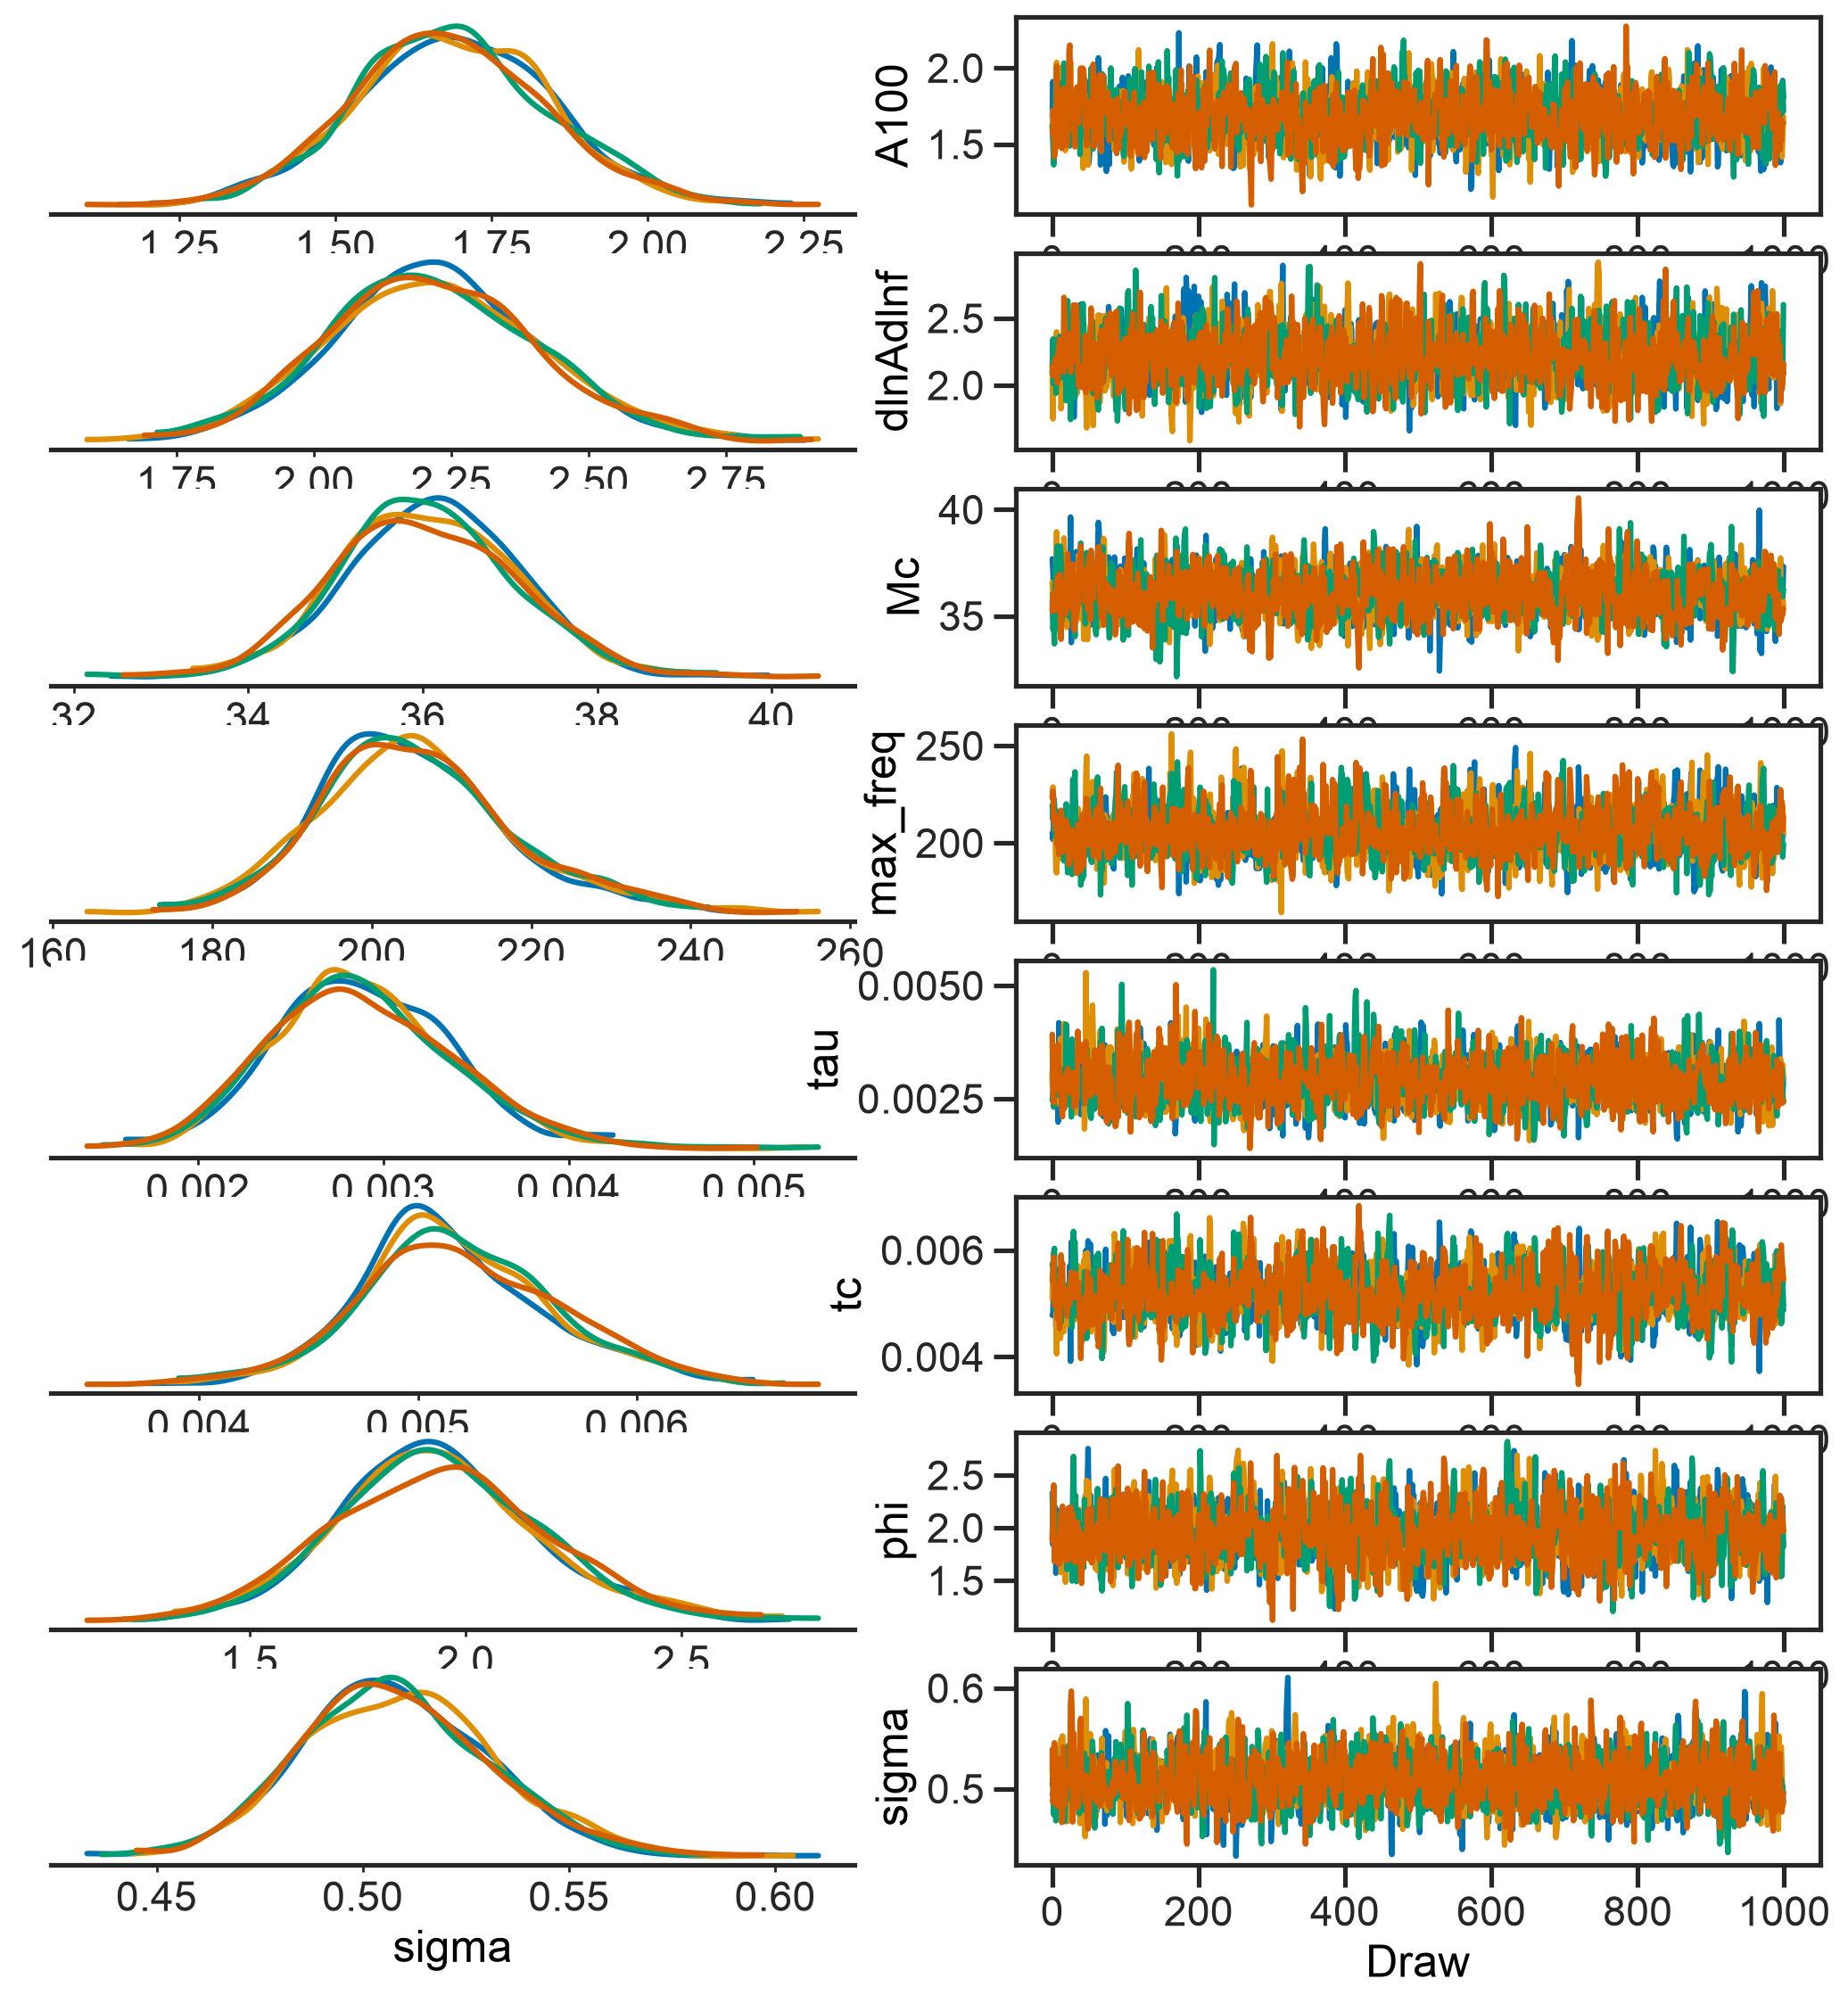

In [24]:
az.plot_trace_dist(az.from_numpyro(fit), var_names=['A100', 'dlnAdlnf', 'Mc', 'max_freq', 'tau', 'tc', 'phi', 'sigma'], compact=False)

In [25]:
chains = fit.get_samples()

Let's look at a few parameters.  First the chirp mass: $\mathcal{M}$.  Note that the true chirp mass of the event is $\sim 30 \, M_\odot$, so our model (which is "0 pN") has *significant* systematic bias!

/var/folders/70/vvk0t38122l6ddxl8hbymr480000gp/T/ipykernel_87192/3516252406.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(chains['Mc'])


Text(0, 0.5, '$p\\left( \\mathcal{M} \\right)$ ($M_\\odot^{-1}$)')

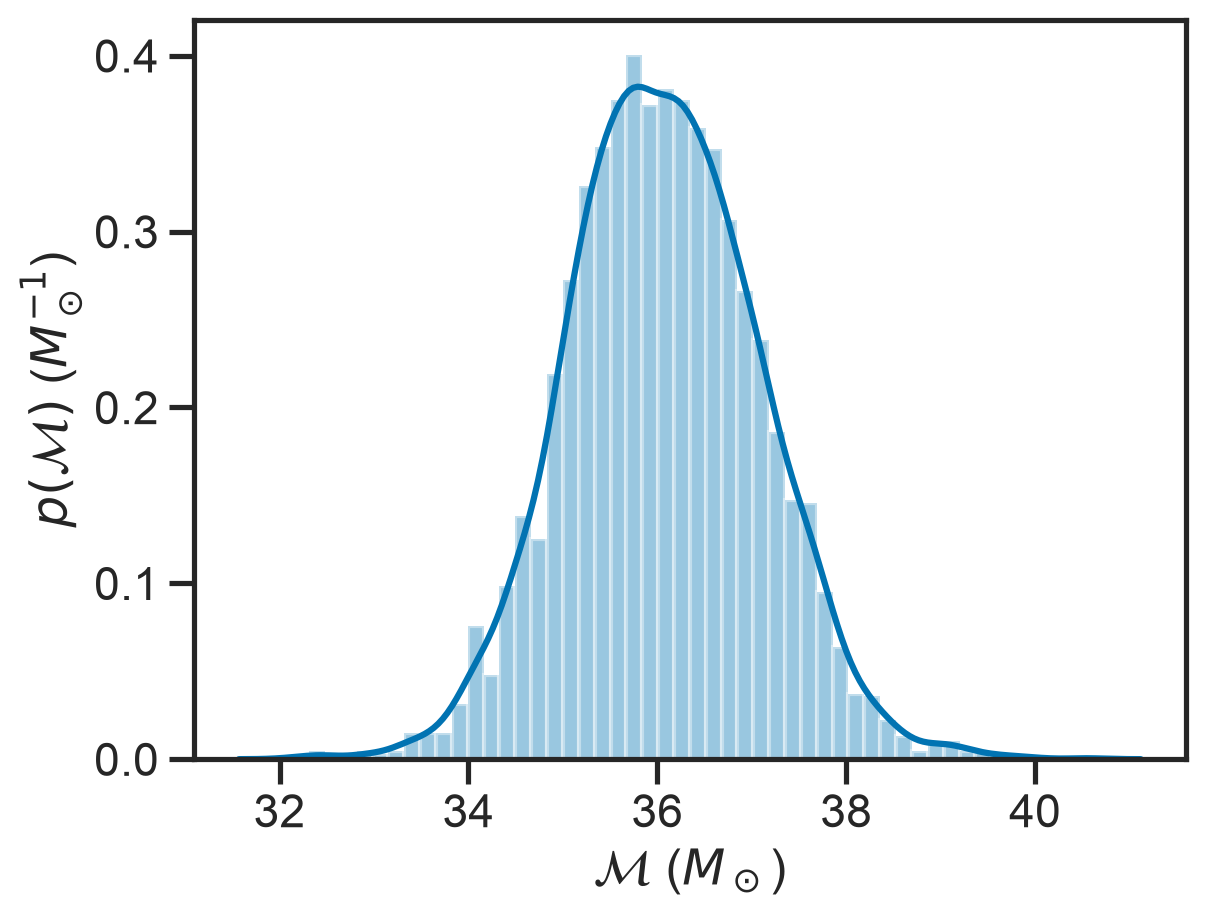

In [26]:
sns.distplot(chains['Mc'])
xlabel(r'$\mathcal{M}$ ($M_\odot$)')
ylabel(r'$p\left( \mathcal{M} \right)$ ($M_\odot^{-1}$)')

The maximum frequency is also interesting:

/var/folders/70/vvk0t38122l6ddxl8hbymr480000gp/T/ipykernel_87192/2934918476.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(chains['max_freq'])


Text(0, 0.5, '$p\\left( f_\\mathrm{max} \\right)$ ($\\mathrm{s}$)')

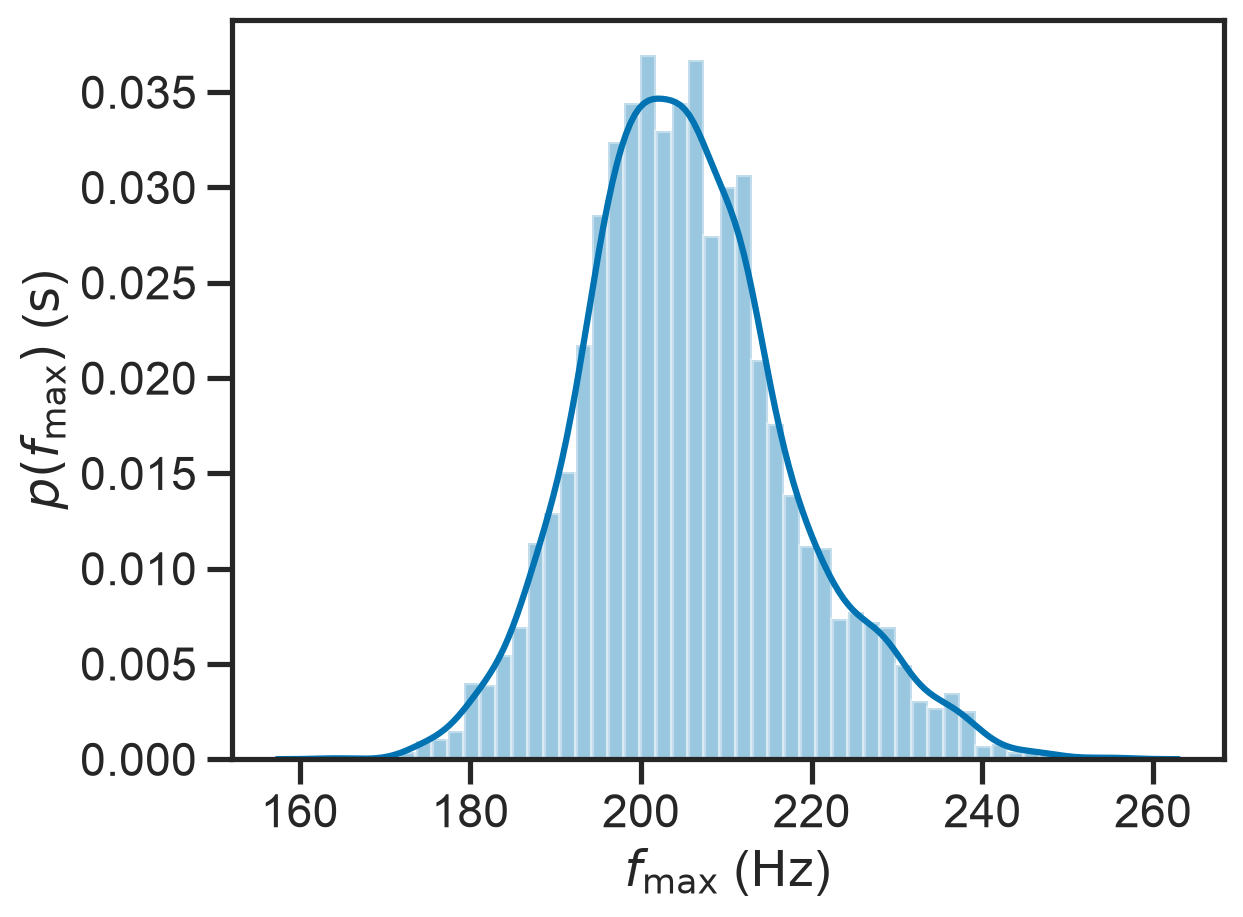

In [27]:
sns.distplot(chains['max_freq'])
xlabel(r'$f_\mathrm{max}$ ($\mathrm{Hz}$)')
ylabel(r'$p\left( f_\mathrm{max} \right)$ ($\mathrm{s}$)')

Now we will plot an uncertainty band on the w.f. from the fit (line is median, dark "$1\sigma$" or 68% interval, light "$2\sigma$ or 95% interval):

Text(0, 0.5, 'Whitened Strain')

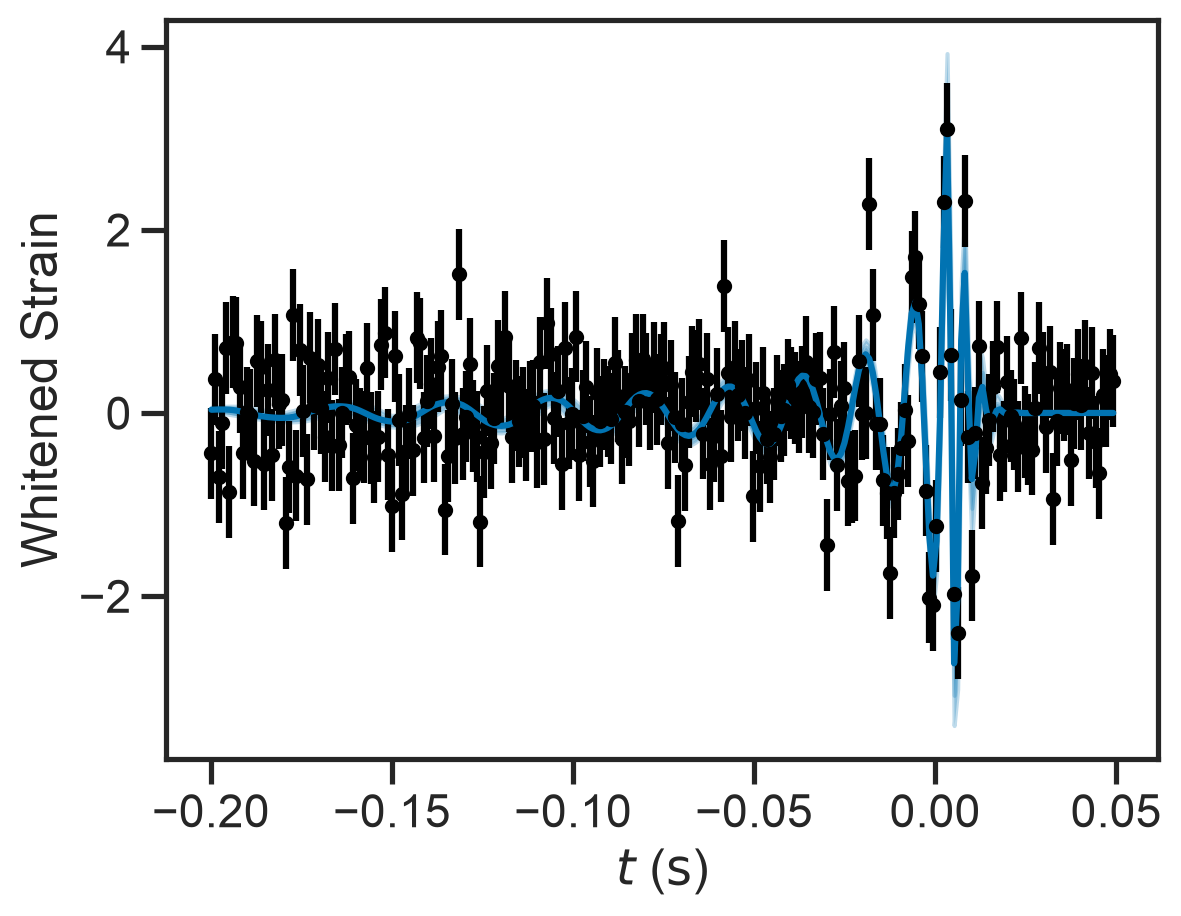

In [28]:
errorbar(white_pass_time, white_pass_strain_h1, 0.5, fmt='.', color='k')
plot(data['ts'], median(chains['h_model'], axis=0))
fill_between(data['ts'], percentile(chains['h_model'], 84, axis=0), percentile(chains['h_model'], 16, axis=0), alpha=0.25, color=sns.color_palette()[0])
fill_between(data['ts'], percentile(chains['h_model'], 97.5, axis=0), percentile(chains['h_model'], 2.5, axis=0), alpha=0.25, color=sns.color_palette()[0])
xlabel(r'$t$ ($\mathrm{s}$)')
ylabel(r'Whitened Strain')

And a corner plot of all the parameters (not waveforms)---things are not terribly correlated.

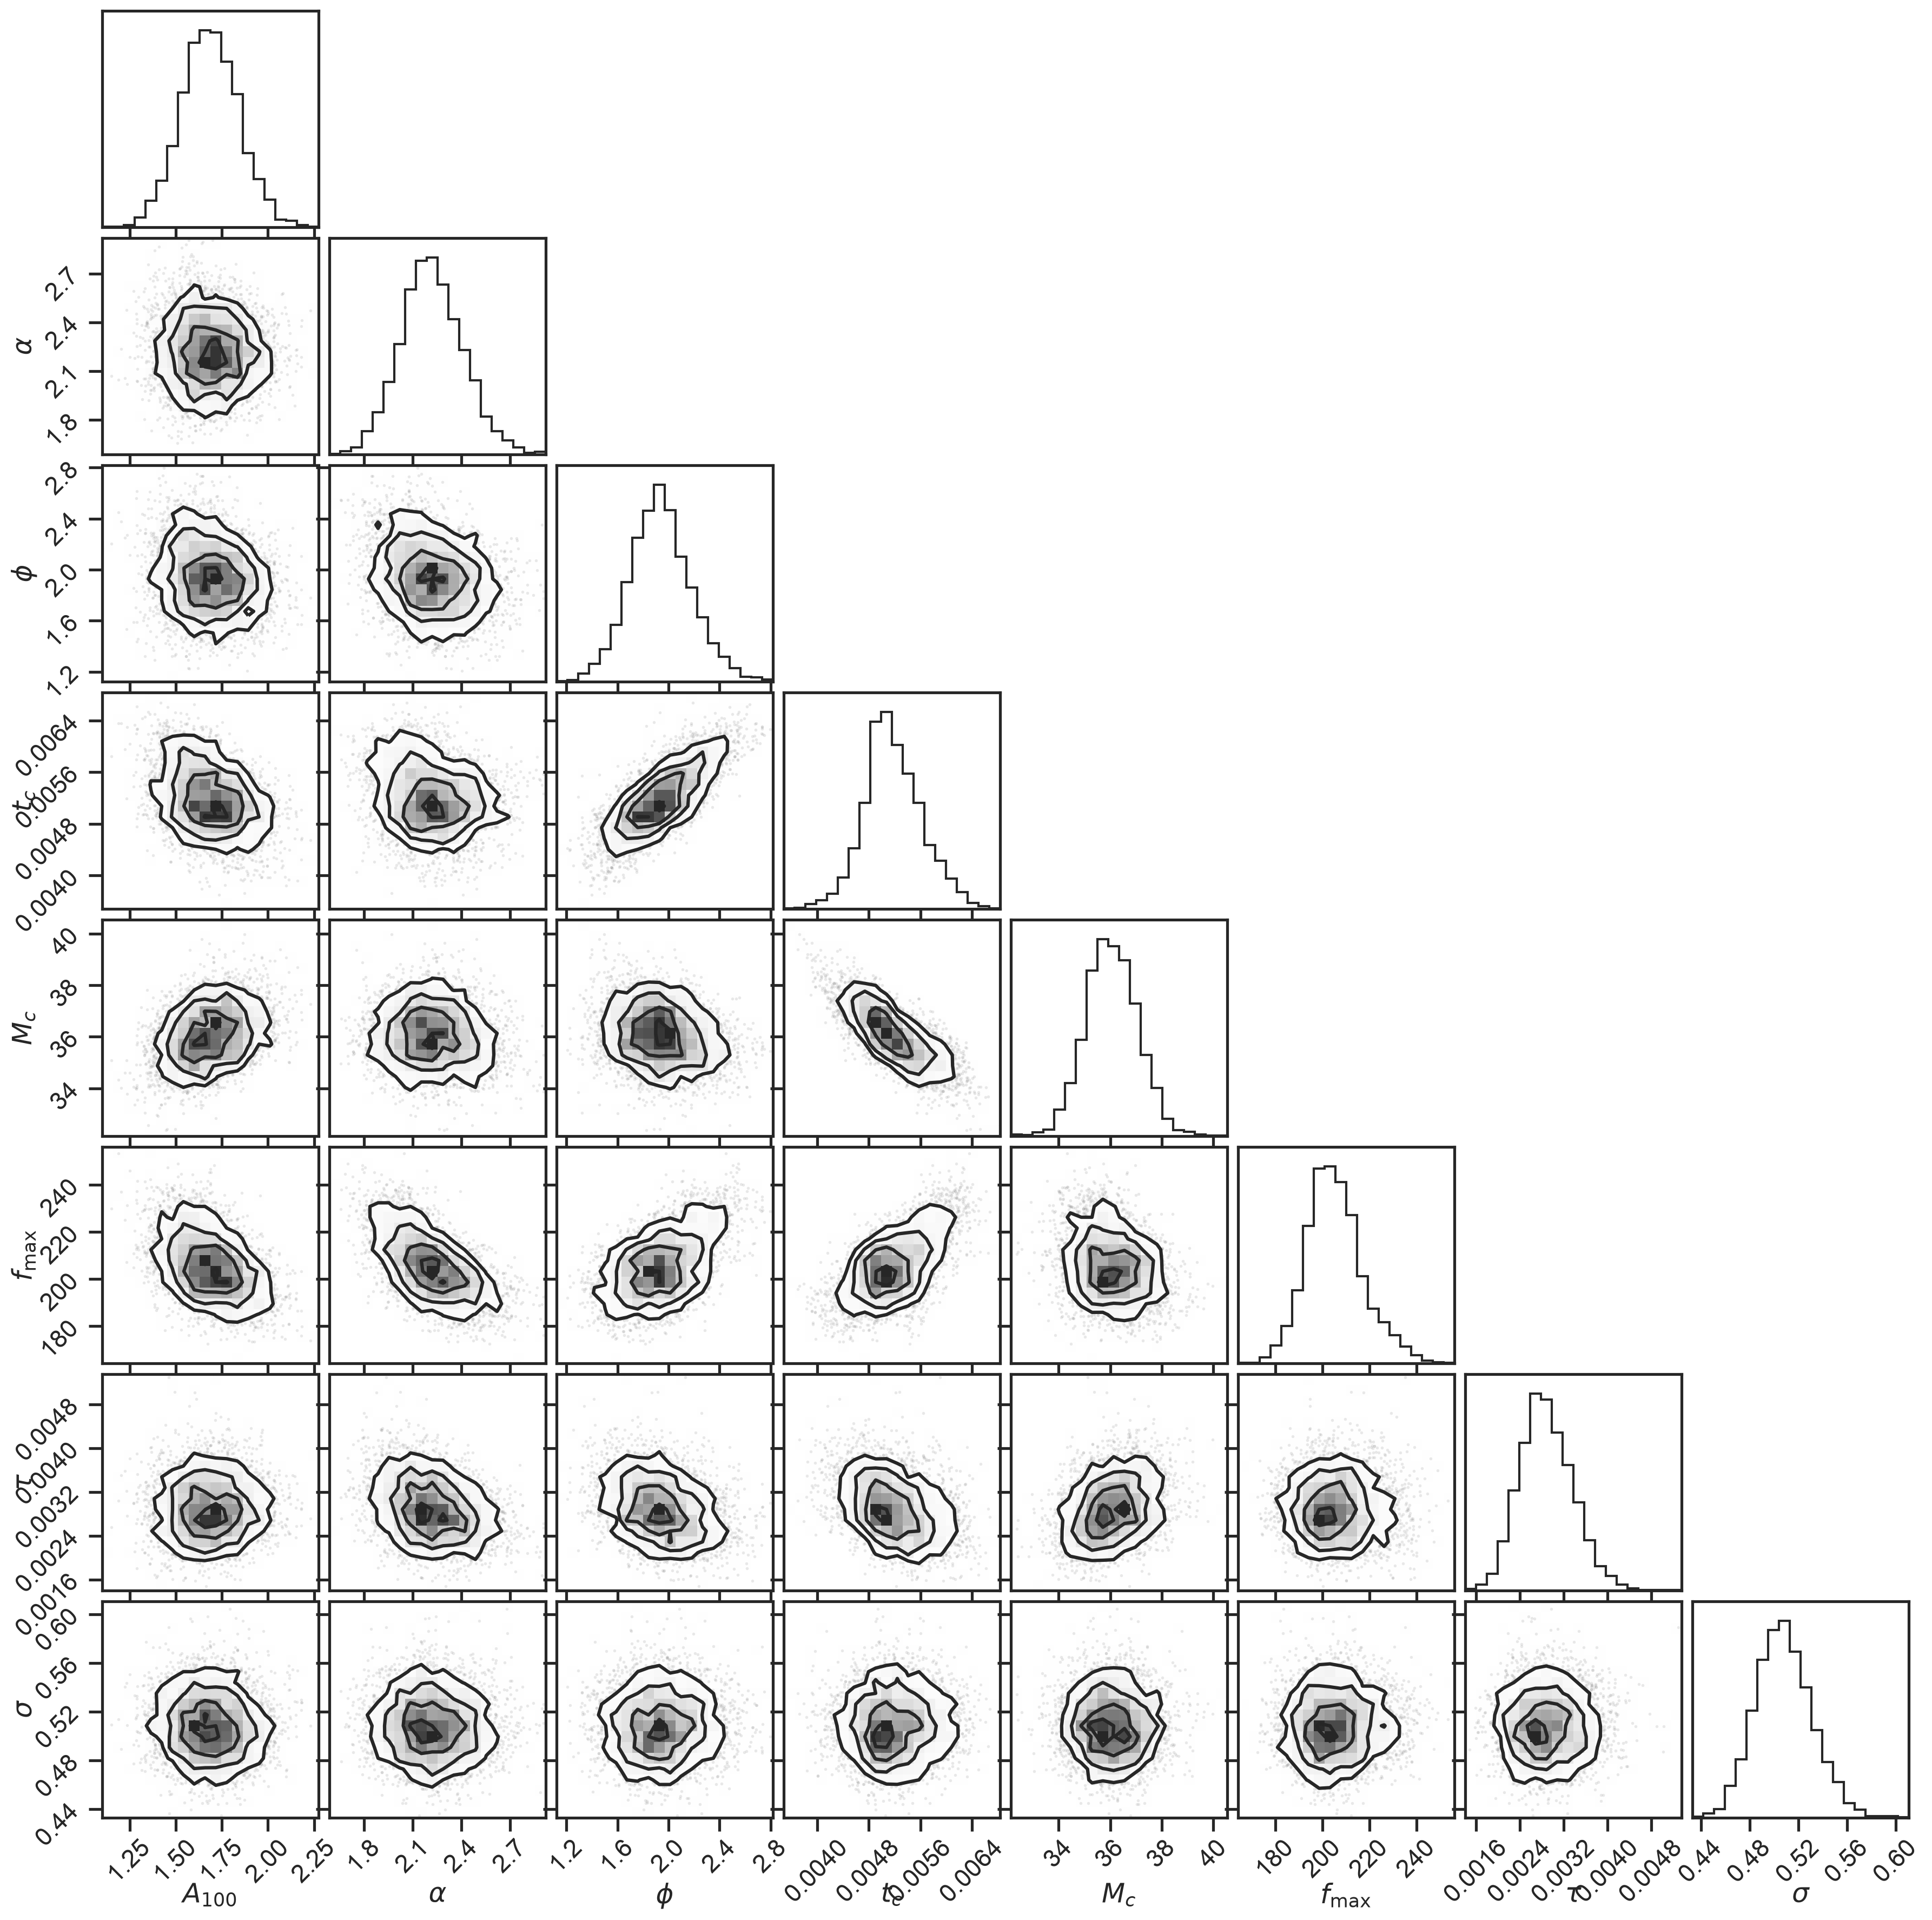

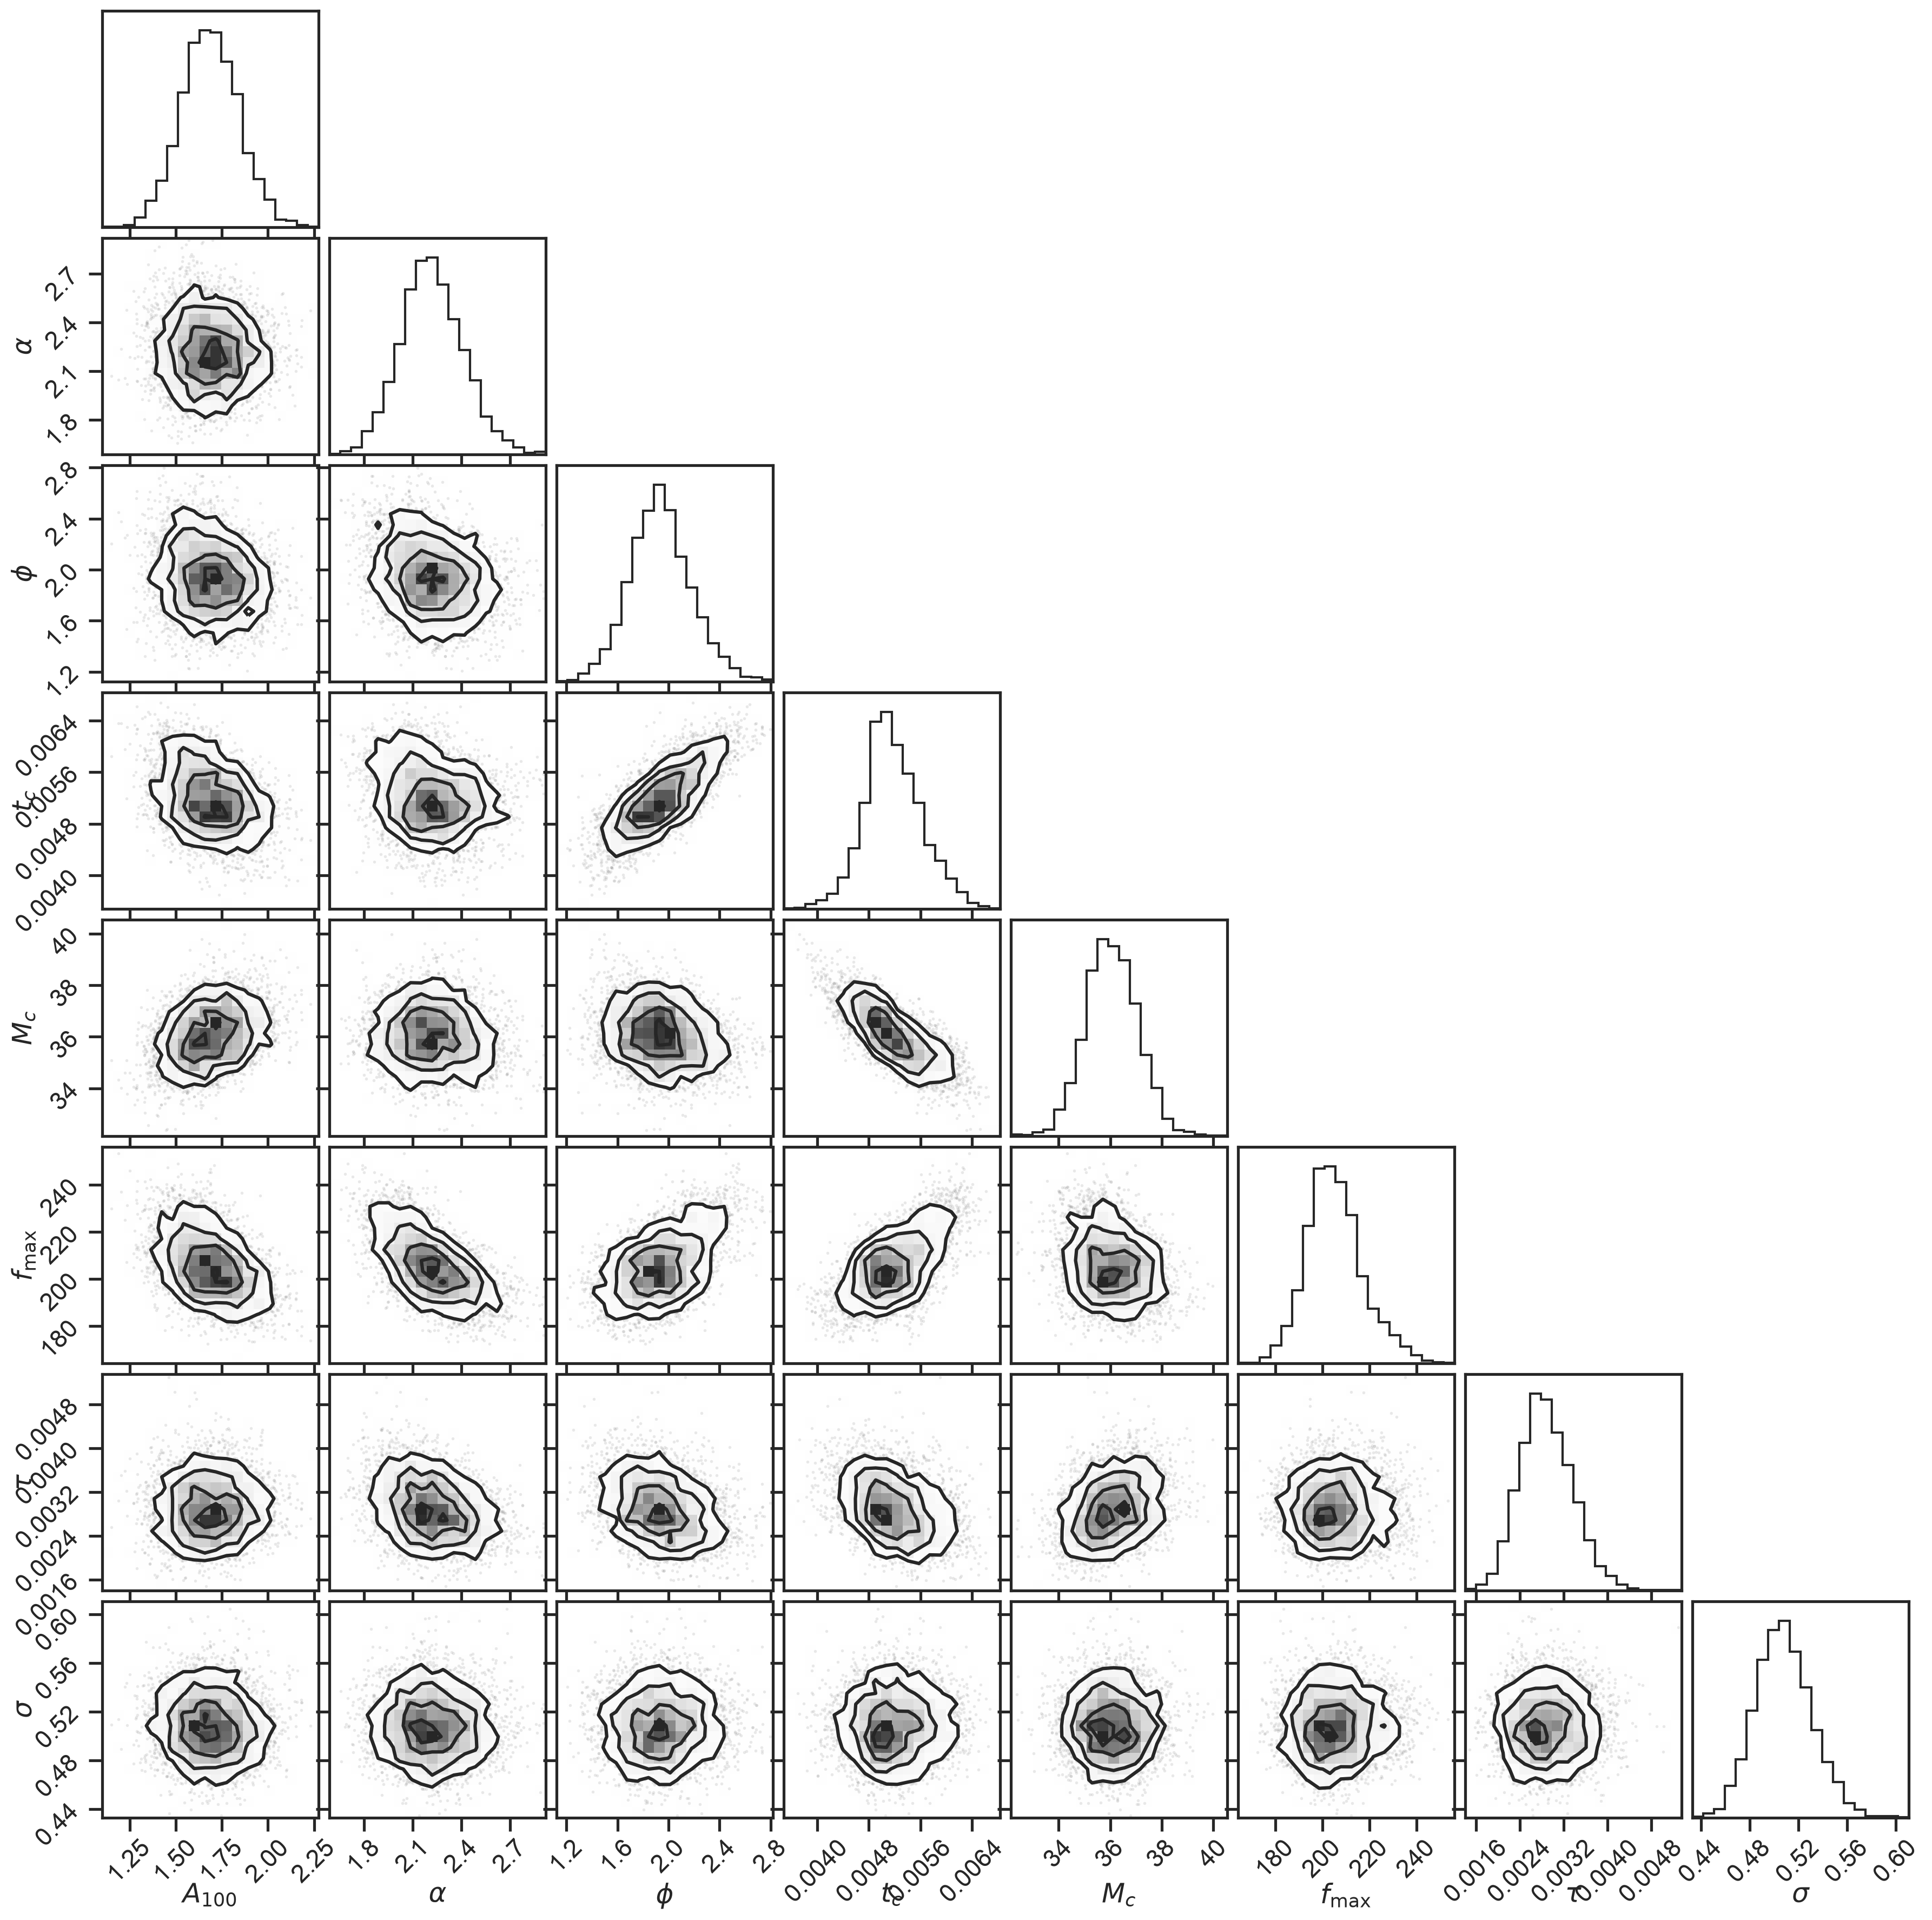

In [29]:
corner.corner(column_stack([chains[k] for k in ['A100', 'dlnAdlnf', 'phi', 'tc', 'Mc', 'max_freq', 'tau', 'sigma']]), labels=[r'$A_{100}$', r'$\alpha$', r'$\phi$', r'$t_c$', r'$M_c$', r'$f_\mathrm{max}$', r'$\tau$', r'$\sigma$'])

We discussed a number of ways we could improve this model:

 * No longer assume stationarity in data (i.e. [BayesWave](https://arxiv.org/abs/1410.3835)).
 * Incorporate more pN terms (and including spin)!
 * Add in additional detector data (requires different amplitude and phase in second detector, as discussed in lecture).
 * Test GR by modifying the phase formula from prediction using chirp mass and mass ratio.